# s4 — skip-safety metrics in the medical domain

Same analysis as `s2_skip_cost_metrics/analysis/s2_metric_analysis.ipynb`, on the s4 combos: chest X-ray backbones (DINOv2-B, RAD-DINO, RAD-DINO-MAIRA-2) × {ChestX-ray14, Chest X-ray Pneumonia} and histopathology backbones (ViT-L, Phikon-v2) × {PatchCamelyon, TCGA-UT}. ChestX-ray14 is used as the original 14-pathology multilabel task (`chestxray14multilabel`); the binary any-finding runs are not part of this analysis. That makes 10 combos.

**Data source.** `USE_TEMP = True` reads `analysis/temp_data/`. That folder holds the defunct group1 / group2 runs, cut down to the s4 combos and spans by `temp_data/make_temp_data.py`. In that data the chest backbones only have skips of length 1–2 (21 spans each), while s4 runs lengths 1–4 (38 spans). Once s4 has finished:
1. run `python thesis/s4_medical_domain/combine_s4.py`, then stage 1 with `bash thesis/s4_medical_domain/launch_s4_metrics.sh` (writes `analysis/output_level_eval_s4_<alias>_<tag>.csv`);
2. run `python metric_experiments/build_group_stats.py --group s4`, which writes `analysis/grouped_metrics_s4_<alias>_<tag>.csv`;
3. set `USE_TEMP = False` and rerun the notebook.

Accuracies are read from `../accuracies/combined/`, which `../combine_s4.py` builds from the split job outputs (`_len1`…`_len4`, `_len12`/`_len34`, `_len1_rerun`). A combo with missing files is skipped and reported, so the notebook also runs on partial results.

Two evaluation measures, both computed per (model, dataset) combo:

- **Spearman's rank correlation** between the metric and the true accuracy of each skip. Every metric is sign-corrected first so that **higher = more similar to the original model = safer to skip**. A positive rho therefore always means the metric points the right way, and a negative rho means it ranks skips backwards.
- **Average top-5 damage.** Damage is the accuracy lost by a skip: baseline accuracy minus skipped-model accuracy. It is averaged over the 5 skips the metric ranks best, in percentage points. It can be slightly negative where a skip beats the baseline.

p-values: two-sided Spearman test for rho, and for top-5 damage a one-sided permutation test against 5 skips drawn at random from the same combo. They are not corrected for multiple comparisons.

**Target: AUROC.** s4 scores skips on AUROC (macro, one-vs-rest for multi-class and multilabel), not accuracy as in s2/s3. The ChestX-ray14 combos only have AUROC, and on the weaker probes accuracy is dominated by seed noise: for DINOv2-B on CXR Pneumonia its seed-to-seed std per skip is 0.032 against AUROC's 0.004. Where both are informative they rank skips alike. So in this notebook "true accuracy" and "damage" mean AUROC and AUROC points. Set `TARGET = "accuracy"` for the accuracy version (the ChestX-ray14 combos stay on AUROC). The linear-probe metrics are not computed for the multilabel combos.

None of these backbones has a usable pretrained classification head on these datasets, so the head metrics from s2 (pretrained head accuracy, KL divergence, flip rate, entropy change) are not available here.

In [1]:
import ast
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from scipy.stats import spearmanr

# ---- data source: flip to False once the s4 results and build_group_stats --group s4 are in ----
USE_TEMP = True
TARGET = "auroc"  # column prefix in the accuracy CSVs: "auroc" (s4 headline), "accuracy" (appendix check), "auprc".
# Temp data has accuracy only. chestxray14multilabel's "accuracy" IS macro-AUROC, so it is on AUROC either way.
TARGET_LABEL = {"auroc": "AUROC", "accuracy": "accuracy", "auprc": "AUPRC"}[TARGET]  # plot titles

S4 = Path.cwd().resolve()
if S4.name == "analysis":
    S4 = S4.parent
ANALYSIS, FIG_DIR = S4 / "analysis", S4 / "figures"
METRICS_DIR = ANALYSIS / "temp_data" if USE_TEMP else ANALYSIS
ACC_DIR = ANALYSIS / "temp_data" if USE_TEMP else S4 / "accuracies" / "combined"  # from combine_s4.py
OUT_DIR = ANALYSIS / "temp_data" if USE_TEMP else ANALYSIS  # where the overview CSV goes
FIG_PREFIX = "s4_temp_" if USE_TEMP else "s4_"
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

MODELS = {"dinov2base": "DINOv2-B", "raddino": "RAD-DINO", "raddinomaira2": "RAD-DINO-MAIRA-2",
          "vitlarge": "ViT-L", "phikonv2": "Phikon-v2"}
DATASETS = {"chestxray14multilabel": "ChestX-ray14", "chestxraypneumonia": "CXR Pneumonia",
            "patchcamelyon": "PatchCamelyon", "tcgaut": "TCGA-UT"}
DOMAINS = {
    "chest": (["dinov2base", "raddino", "raddinomaira2"], ["chestxray14multilabel", "chestxraypneumonia"]),
    "histo": (["vitlarge", "phikonv2"], ["patchcamelyon", "tcgaut"]),
}
COMBOS = [(m, d) for models, datasets in DOMAINS.values() for m in models for d in datasets]

# Thesis metrics, in plot order, grouped by where they are measured.
THESIS_METRICS = {
    "toast_linear_error": "Linear approx. error (TOAST)",
    "angular_dist": "Angular distance",
    "local_cka": "Local CKA",
    "cka_embed": "Global CKA",
    "cosine_sim": "Cosine similarity",
    "mse": "MSE",
}
TIERS = [("Local (skip boundary)", 3), ("Global (final embedding)", 3)]

# Every other stage-1 metric, for the appendix (columns with no values are dropped there).
OTHER_METRICS = {
    "knn_overlap@5": "kNN overlap@5",
    "knn_overlap@10": "kNN overlap@10",
    "participation_ratio_change": "Participation ratio change",
    "probe_frozen_accuracy": "Frozen linear probe accuracy",
    "probe_refit_accuracy": "Refit linear probe accuracy",
    "kl_div": "KL divergence",
    "top1_flip_pct": "Top-1 flip rate",
    "entropy_delta": "Entropy change",
}

N_PERM = 20_000  # random 5-skip draws per combo for the top-5 damage p-value

# Raw value grows with dissimilarity -> negated so higher = safer for every metric.
DISSIMILARITY_METRICS = {"toast_linear_error", "angular_dist", "mse", "kl_div", "top1_flip_pct",
                         "entropy_delta", "participation_ratio_change"}
print(f"data: {'TEMP (group1/group2 stand-in)' if USE_TEMP else 's4'}  target: {TARGET}")

data: TEMP (group1/group2 stand-in)  target: accuracy


## Load

One row per (model, dataset, span). `true_accuracy` is taken from the accuracy CSVs (the `TARGET` column), not from the grouped file, so `TARGET` can be switched without rebuilding. The completeness table compares the spans loaded with the spans in that combo's s4 configs.

In [2]:
def _span(approx_layer):
    parsed = ast.literal_eval(approx_layer)
    return f"({parsed[0][0]},{parsed[0][1]})" if len(parsed) == 1 else None


def _config_spans(model, tag):
    spans = set()
    for p in sorted((S4 / "configs").glob(f"experiments_{model}_{tag}*.csv")):
        spans |= {s for s in pd.read_csv(p)["skip"].map(_span) if s}
    return spans


frames, baselines, status = [], {}, []
for model, tag in COMBOS:
    acc_paths = [p for p in [ACC_DIR / f"accuracies_results_{model}_{tag}.csv"] if p.exists()]
    metrics_path = METRICS_DIR / f"grouped_metrics_s4_{model}_{tag}.csv"
    row = {"model": model, "dataset": tag, "acc_files": len(acc_paths), "metrics_file": metrics_path.exists()}
    if not acc_paths or not metrics_path.exists():
        status.append({**row, "loaded": False})
        continue
    acc = pd.read_csv(acc_paths[0])
    base = acc.loc[acc["approx_layer"] == "[]", f"{TARGET}_mean"]
    if base.empty:
        status.append({**row, "loaded": False, "note": "no baseline row"})
        continue
    baselines[(model, tag)] = base.iloc[0]
    acc["span"] = acc["approx_layer"].map(_span)
    truth = acc.dropna(subset=["span"]).set_index("span")[f"{TARGET}_mean"]

    g = pd.read_csv(metrics_path).drop(columns=["true_accuracy"])
    g["true_accuracy"] = g["span"].map(truth)
    g = g.dropna(subset=["true_accuracy"])
    g.insert(0, "dataset", tag)
    g.insert(0, "model", model)
    frames.append(g)

    expected = _config_spans(model, tag)
    status.append({**row, "loaded": True, "spans": len(g), "s4_spans": len(expected),
                   "missing": len(expected - set(g["span"]))})

status = pd.DataFrame(status).set_index(["model", "dataset"])
if not frames:
    display(status)
    raise FileNotFoundError(f"no combo loaded from {METRICS_DIR} / {ACC_DIR}; see the table above")
raw = pd.concat(frames, ignore_index=True)

df = raw.copy()
for m in DISSIMILARITY_METRICS & set(df.columns):
    df[m] = -df[m]

combos = [c for c in COMBOS if c in baselines]  # loaded combos, chest first then histo
summary = raw.groupby(["model", "dataset"], sort=False).agg(
    spans=("span", "size"), best_skip_acc=("true_accuracy", "max"),
    best_span=("span", lambda s: s.iloc[raw.loc[s.index, "true_accuracy"].argmax()]))
summary.insert(0, "baseline_acc", [baselines[c] for c in summary.index])
display(status)
summary

acc_files  metrics_file  loaded  spans  s4_spans  missing
model         dataset                                                                      
dinov2base    chestxray14                 1          True    True     21        38       17
              chestxraypneumonia          1          True    True     21        38       17
raddino       chestxray14                 1          True    True     21        38       17
              chestxraypneumonia          1          True    True     21        38       17
raddinomaira2 chestxray14                 1          True    True     21        38       17
              chestxraypneumonia          1          True    True     21        38       17
vitlarge      patchcamelyon               1          True    True     86        86        0
              tcgaut                      1          True    True     86        86        0
phikonv2      patchcamelyon               1          True    True     86        86        0
              tcgaut                      1          True    True     86        86        0

baseline_acc  spans  best_skip_acc best_span
model         dataset                                                         
dinov2base    chestxray14             0.644528     21       0.659730     (6,7)
              chestxraypneumonia      0.811432     21       0.857906    (9,11)
raddino       chestxray14             0.690897     21       0.707516     (7,9)
              chestxraypneumonia      0.941774     21       0.948184     (2,4)
raddinomaira2 chestxray14             0.646064     21       0.656558   (10,11)
              chestxraypneumonia      0.919338     21       0.925214    (9,10)
vitlarge      patchcamelyon           0.816457     86       0.850962    (9,10)
              tcgaut                  0.611911     86       0.634182    (8,12)
phikonv2      patchcamelyon           0.888092     86       0.893962     (0,2)
              tcgaut                  0.818021     86       0.818111     (0,1)

### Polarity check

The sign correction must match the data. Every flipped metric should correlate negatively with true accuracy before flipping and every other metric positively, and the corrected rho must be exactly −1 × raw for flipped metrics. The second condition is a bug check and is asserted. The first only warns, because in a new domain a metric that points the wrong way on most combos is a finding, not a bug.

In [3]:
polarity = []
for m in THESIS_METRICS:
    raw_r, cor_r = [], []
    for key in combos:
        idx = raw[(raw["model"] == key[0]) & (raw["dataset"] == key[1])].dropna(subset=[m]).index
        if len(idx) < 3:
            continue
        raw_r.append(spearmanr(raw.loc[idx, m], raw.loc[idx, "true_accuracy"])[0])
        cor_r.append(spearmanr(df.loc[idx, m], df.loc[idx, "true_accuracy"])[0])
    if not raw_r:
        continue
    raw_r, cor_r = np.array(raw_r), np.array(cor_r)
    flipped = m in DISSIMILARITY_METRICS
    polarity.append({
        "metric": THESIS_METRICS[m], "flipped": flipped,
        "raw rho > 0": int((raw_r > 0).sum()), "raw rho < 0": int((raw_r < 0).sum()),
        "median raw rho": np.median(raw_r),
        "corrected = ±raw": np.allclose(cor_r, -raw_r if flipped else raw_r),
    })
polarity = pd.DataFrame(polarity).set_index("metric")
polarity["sign check"] = np.where(polarity["flipped"], polarity["median raw rho"] < 0, polarity["median raw rho"] > 0)
assert polarity["corrected = ±raw"].all()
if not polarity["sign check"].all():
    print("WARNING: median rho has the unexpected sign for:", list(polarity.index[~polarity["sign check"]]))
polarity.round(2)

,flipped,raw rho > 0,raw rho < 0,median raw rho,corrected = ±raw,sign check
metric,,,,,,
Linear approx. error (TOAST),True,1,9,-0.24,True,True
Angular distance,True,1,9,-0.31,True,True
Local CKA,False,9,1,0.35,True,True
Global CKA,False,8,2,0.28,True,True
Cosine similarity,False,8,2,0.28,True,True
MSE,True,4,6,-0.29,True,True


## Spearman rho and average top-5 damage

Rows are (model, dataset) combos. A metric with no values for a combo is left as NaN.

In [4]:
def evaluate(metrics):
    rho, rho_p, damage, damage_p = {}, {}, {}, {}
    rng = np.random.default_rng(0)
    for key in combos:
        sub = df[(df["model"] == key[0]) & (df["dataset"] == key[1])]
        rho[key], rho_p[key], damage[key], damage_p[key] = {}, {}, {}, {}
        for m in metrics:
            if m not in sub:
                continue
            s = sub.dropna(subset=[m])
            if len(s) < 3 or s[m].std() == 0:
                continue
            rho[key][m], rho_p[key][m] = spearmanr(s[m], s["true_accuracy"])
            top5 = s.sort_values(m, ascending=False)["true_accuracy"].iloc[:5]
            damage[key][m] = (baselines[key] - top5.mean()) * 100
            # Null: mean accuracy of 5 skips drawn at random (without replacement) from the same pool.
            acc = s["true_accuracy"].to_numpy()
            draws = np.argsort(rng.random((N_PERM, len(acc))), axis=1)[:, :5]
            null_means = acc[draws].mean(axis=1)
            damage_p[key][m] = ((null_means >= top5.mean()).sum() + 1) / (N_PERM + 1)
    as_frame = lambda d: pd.DataFrame(d).T.reindex(index=combos, columns=list(metrics))
    return as_frame(rho), as_frame(rho_p), as_frame(damage), as_frame(damage_p)


def pretty_index(index):
    return [f"{MODELS[m]} / {DATASETS[d]}" for m, d in index]


rho, rho_p, damage, damage_p = evaluate(THESIS_METRICS)
pd.concat({"spearman_rho": rho, "rho_p": rho_p, "top5_damage_pp": damage, "damage_p": damage_p},
          axis=1).round(3)

spearman_rho                                                                 rho_p                                                        top5_damage_pp                                                     \
                                 toast_linear_error angular_dist local_cka cka_embed cosine_sim    mse toast_linear_error angular_dist local_cka cka_embed cosine_sim    mse toast_linear_error angular_dist local_cka cka_embed cosine_sim    mse   
dinov2base    chestxray14                     0.051        0.622     0.444    -0.029      0.664  0.462              0.827        0.003     0.044     0.902      0.001  0.035              0.477       -0.154     1.172     0.894     -0.075 -0.039   
              chestxraypneumonia              0.441        0.133     0.347     0.407     -0.101 -0.346              0.045        0.567     0.123     0.067      0.664  0.124             -0.897        0.032    -0.791    -1.368      0.288  1.122   
raddino       chestxray14                     0.722        0.217     0.034     0.271      0.397 -0.716              0.000        0.345     0.884     0.234      0.074  0.000             -0.775       -0.496    -0.447    -0.525     -0.705 -0.122   
              chestxraypneumonia              0.229        0.248     0.117    -0.102     -0.257 -0.214              0.319        0.279     0.613     0.661      0.260  0.351             -0.438       -0.406    -0.321    -0.160     -0.128 -0.171   
raddinomaira2 chestxray14                     0.253       -0.047    -0.064     0.290      0.206 -0.092              0.268        0.841     0.784     0.203      0.369  0.691             -0.011        0.137    -0.222    -0.156     -0.222 -0.222   
              chestxraypneumonia              0.139        0.566     0.341     0.202      0.305  0.341              0.549        0.008     0.130     0.381      0.179  0.131              0.534       -0.021     0.053     0.064      0.064  0.064   
vitlarge      patchcamelyon                   0.259        0.364     0.551     0.285      0.386  0.407              0.016        0.001     0.000     0.008      0.000  0.000             -0.903       -2.523    -1.958    -1.852     -2.523 -2.523   
              tcgaut                          0.364        0.112     0.347     0.205      0.249  0.249              0.001        0.305     0.001     0.059      0.021  0.021             -0.273       -0.027    -0.089    -0.027     -0.027 -0.027   
phikonv2      patchcamelyon                  -0.109        0.533     0.617     0.333      0.194  0.344              0.317        0.000     0.000     0.002      0.073  0.001             -0.016       -0.117    -0.133     0.049      0.046 -0.133   
              tcgaut                          0.014        0.867     0.820     0.403      0.610  0.525              0.897        0.000     0.000     0.000      0.000  0.000              0.385        0.148     0.154     0.120      0.085  0.045   

                                           damage_p                                                     
                                 toast_linear_error angular_dist local_cka cka_embed cosine_sim    mse  
dinov2base    chestxray14                     0.153        0.008     0.479     0.336      0.014  0.020  
              chestxraypneumonia              0.048        0.317     0.068     0.010      0.433  0.839  
raddino       chestxray14                     0.076        0.471     0.558     0.408      0.136  0.987  
              chestxraypneumonia              0.036        0.060     0.222     0.651      0.719  0.623  
raddinomaira2 chestxray14                     0.662        0.866     0.256     0.383      0.257  0.256  
              chestxraypneumonia              0.637        0.053     0.099     0.102      0.099  0.105  
vitlarge      patchcamelyon                   0.328        0.002     0.022     0.029      0.001  0.001  
              tcgaut                          0.272        0.306     0.301     0.310      0.308  0.310  
phikonv2      patchcamelyon         

## Thesis figures

The outlined cell in each row is that combo's best metric (highest rho / lowest damage). Grey = not available for that combo. Stars mark significance: * p < .05, ** p < .01, *** p < .001 (tests described in the intro). The white horizontal line separates the chest and histopathology combos.

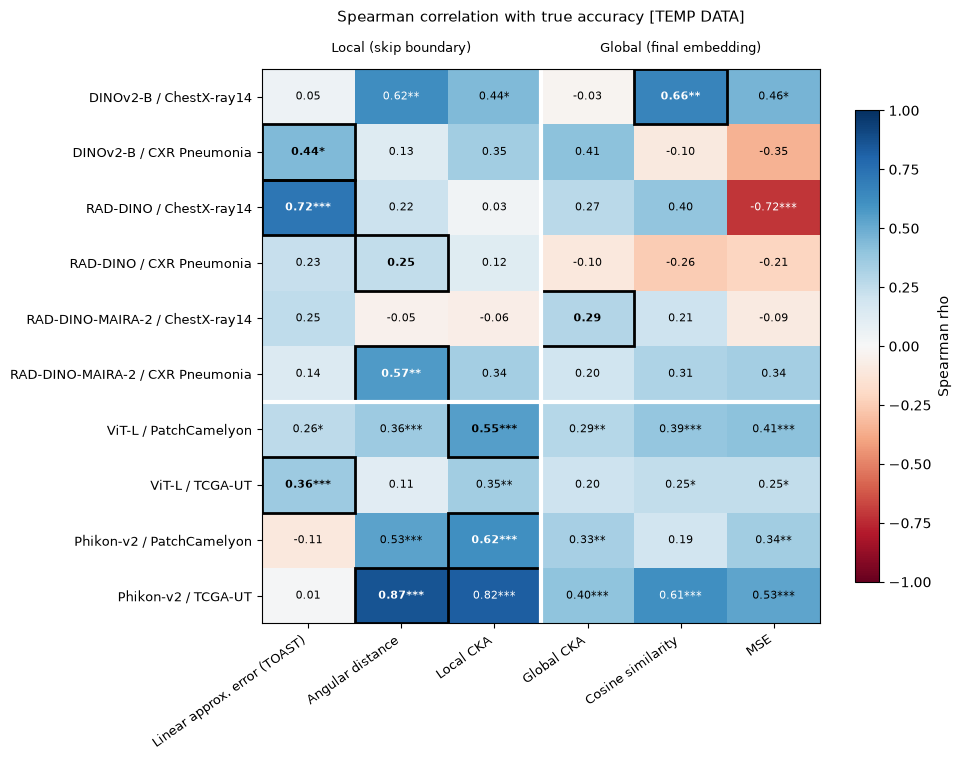

In [5]:
def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def heatmap(mat, title, cbar_label, cmap, vmin, vmax, fmt, best, names, tiers=None, out=None, pvals=None):
    mat = mat.rename(columns=names)
    values = mat.values.astype(float)
    fig, ax = plt.subplots(figsize=(1.05 * mat.shape[1] + 3.5, 0.55 * mat.shape[0] + 2.2))
    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad("#e6e6e6")
    norm = Normalize(vmin=vmin, vmax=vmax)
    im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap_obj, norm=norm, aspect="auto")

    for i in range(values.shape[0]):
        row = values[i]
        best_j = None if np.isnan(row).all() else (np.nanargmax(row) if best == "max" else np.nanargmin(row))
        for j, v in enumerate(row):
            if np.isnan(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=7, color="#888888")
                continue
            r, g, b, _ = cmap_obj(norm(v))
            colour = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.55 else "black"
            label = fmt.format(v) + ("" if pvals is None else stars(pvals.iat[i, j]))
            ax.text(j, i, label, ha="center", va="center", fontsize=8, color=colour,
                    fontweight="bold" if j == best_j else "normal")
        if best_j is not None:
            ax.add_patch(Rectangle((best_j - 0.5, i - 0.5), 1, 1, fill=False, lw=2, ec="black"))

    # Separate the chest and histopathology rows.
    n_chest = sum(m in DOMAINS["chest"][0] for m, _ in mat.index)
    if 0 < n_chest < len(mat):
        ax.axhline(n_chest - 0.5, color="white", lw=3)

    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=35, ha="right", fontsize=9)
    ax.set_yticks(range(mat.shape[0]))
    ax.set_yticklabels(pretty_index(mat.index), fontsize=9)
    if tiers:
        start = 0
        for label, width in tiers:
            if start:
                ax.axvline(start - 0.5, color="white", lw=3)
            ax.text(start + width / 2 - 0.5, -0.75, label, ha="center", va="bottom", fontsize=9)
            start += width
    ax.set_title(title + (" [TEMP DATA]" if USE_TEMP else ""), fontsize=11, pad=34 if tiers else 8)
    fig.colorbar(im, ax=ax, shrink=0.85, label=cbar_label)
    fig.tight_layout()
    if out:
        fig.savefig(FIG_DIR / f"{FIG_PREFIX}{out}", dpi=200, bbox_inches="tight")
    plt.show()


heatmap(rho, f"Spearman correlation with true {TARGET_LABEL}", "Spearman rho", "RdBu", -1, 1, "{:.2f}",
        "max", THESIS_METRICS, TIERS, "spearman_rho.png", pvals=rho_p)

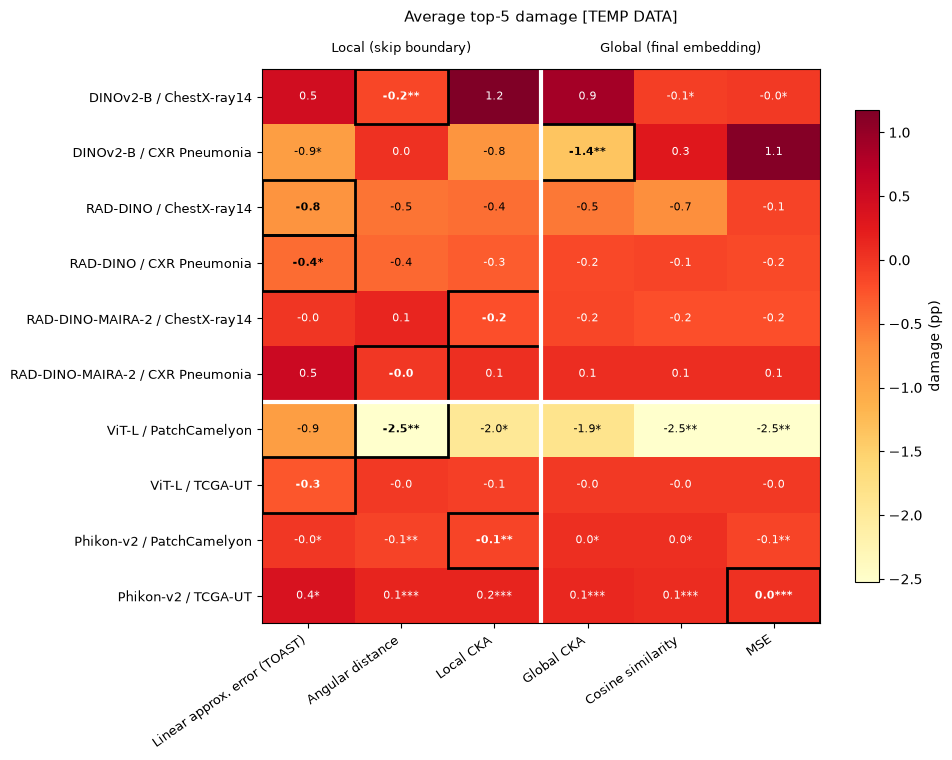

In [6]:
heatmap(damage, "Average top-5 damage", "damage (pp)", "YlOrRd", min(0, np.nanmin(damage.values)),
        np.nanmax(damage.values), "{:.1f}", "min", THESIS_METRICS, TIERS, "top5_damage.png",
        pvals=damage_p)

## Summary

Mean over combos, overall and per domain. `best_in` counts combos where the metric has the lowest damage among the metrics available there. Tied metrics each get the count.

In [7]:
def overview_table(rho, damage):
    best_counts = damage.apply(lambda r: r == r.min(), axis=1).sum()
    return pd.DataFrame({
        "metric": [THESIS_METRICS[m] for m in THESIS_METRICS],
        "n_combos": rho.notna().sum().values,
        "mean_rho": rho.mean().values,
        "min_rho": rho.min().values,
        "mean_top5_damage_pp": damage.mean().values,
        "max_top5_damage_pp": damage.max().values,
        "best_in": best_counts.values,
    }).set_index("metric")


overview = overview_table(rho, damage)
overview.to_csv(OUT_DIR / "metric_overview_s4.csv")

by_domain = {}
for domain, (models, _) in DOMAINS.items():
    rows = [k for k in rho.index if k[0] in models]
    by_domain[domain] = overview_table(rho.loc[rows], damage.loc[rows])[["mean_rho", "min_rho", "mean_top5_damage_pp", "best_in"]]
display(overview.round(2))
pd.concat(by_domain, axis=1).round(2)

,n_combos,mean_rho,min_rho,mean_top5_damage_pp,max_top5_damage_pp,best_in
metric,,,,,,
Linear approx. error (TOAST),10,0.24,-0.11,-0.19,0.53,3
Angular distance,10,0.36,-0.05,-0.34,0.15,3
Local CKA,10,0.36,-0.06,-0.26,1.17,2
Global CKA,10,0.23,-0.10,-0.30,0.89,1
Cosine similarity,10,0.27,-0.26,-0.32,0.29,2
MSE,10,0.10,-0.72,-0.20,1.12,4


chest                                        histo                                    
                             mean_rho min_rho mean_top5_damage_pp best_in mean_rho min_rho mean_top5_damage_pp best_in
metric                                                                                                                
Linear approx. error (TOAST)     0.31    0.05               -0.19       2     0.13   -0.11               -0.20       1
Angular distance                 0.29   -0.05               -0.15       2     0.47    0.11               -0.63       1
Local CKA                        0.20   -0.06               -0.09       1     0.58    0.35               -0.51       1
Global CKA                       0.17   -0.10               -0.21       1     0.31    0.20               -0.43       0
Cosine similarity                0.20   -0.26               -0.13       1     0.36    0.19               -0.60       1
MSE                             -0.09   -0.72                0.11       1     0.38    0.25               -0.66       3

## Summary figure: angular distance vs the other metrics

One row per metric. Small dots are the individual (model, dataset) combos, coloured by domain; the large dot is the mean over combos. Angular distance is highlighted.

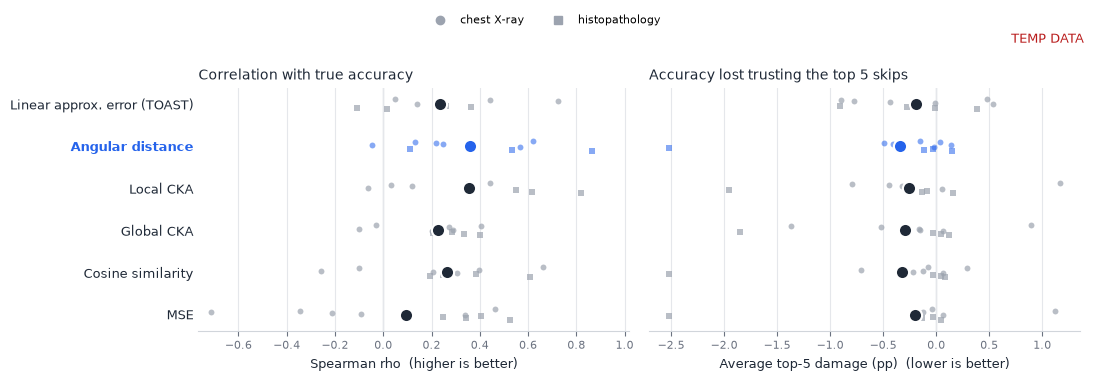

In [8]:
ACCENT, NEUTRAL, INK, MUTED = "#2563eb", "#9ca3af", "#1f2937", "#6b7280"
DOMAIN_MARKERS = {"chest": "o", "histo": "s"}


def dot_panel(ax, mat, xlabel, better):
    labels = []
    for y, m in enumerate(THESIS_METRICS):
        col = mat[m].dropna()
        hi = m == "angular_dist"
        jitter = np.linspace(-0.12, 0.12, len(col)) if len(col) > 1 else np.zeros(1)
        for domain, (models, _) in DOMAINS.items():
            sel = np.array([k[0] in models for k in col.index])
            ax.scatter(col.values[sel], y + jitter[sel], s=18, marker=DOMAIN_MARKERS[domain],
                       color=ACCENT if hi else NEUTRAL, alpha=0.55 if hi else 0.7, linewidths=0, zorder=2)
        ax.scatter([col.mean()], [y], s=90, color=ACCENT if hi else INK,
                   edgecolors="white", linewidths=1.5, zorder=3)
        labels.append(THESIS_METRICS[m] + (f" ({len(col)} combos)" if len(col) < len(combos) else ""))
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=9)
    for tick, m in zip(ax.get_yticklabels(), THESIS_METRICS):
        tick.set_color(ACCENT if m == "angular_dist" else INK)
        tick.set_fontweight("bold" if m == "angular_dist" else "normal")
    ax.set_xlabel(f"{xlabel}  ({better} is better)", fontsize=9, color=INK)
    ax.grid(axis="x", color="#e5e7eb", lw=0.8, zorder=0)
    ax.tick_params(axis="x", labelsize=8, colors=MUTED)
    ax.tick_params(axis="y", length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#d1d5db")


fig, (ax_r, ax_g) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ax_r.invert_yaxis()  # shared y-axis: invert once, not per panel
dot_panel(ax_r, rho, "Spearman rho", "higher")
ax_r.axvline(0, color=MUTED, lw=0.8, zorder=1)
ax_r.set_xlim(min(-0.3, np.nanmin(rho.values) - 0.05), 1.02)
dot_panel(ax_g, damage, "Average top-5 damage (pp)", "lower")
ax_g.axvline(0, color=MUTED, lw=0.8, zorder=1)
ax_r.set_title(f"Correlation with true {TARGET_LABEL}", fontsize=10, loc="left", color=INK)
ax_g.set_title(f"{TARGET_LABEL[0].upper() + TARGET_LABEL[1:]} lost trusting the top 5 skips", fontsize=10, loc="left", color=INK)
handles = [plt.Line2D([], [], marker=DOMAIN_MARKERS[d], ls="", color=NEUTRAL, label=l)
           for d, l in [("chest", "chest X-ray"), ("histo", "histopathology")]]
fig.legend(handles=handles, fontsize=8, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.06))
if USE_TEMP:
    fig.suptitle("TEMP DATA", fontsize=9, color="#b91c1c", x=0.99, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}metric_summary.png", dpi=200, bbox_inches="tight")
plt.show()

### Findings (numbers computed below)

In [9]:
shared = [m for m in THESIS_METRICS if rho[m].notna().sum() == len(combos)]
o = overview.rename(index={v: k for k, v in THESIS_METRICS.items()})
others = o.loc[shared].drop("angular_dist")
a = o.loc["angular_dist"]
rank = lambda col, asc: int(o.loc[shared, col].rank(ascending=asc, method="min")["angular_dist"])
print(f"Among the {len(shared)} metrics available on all {len(combos)} combos, angular distance has:")
for col, asc, label, unit in [("mean_rho", False, "mean rho", ""), ("min_rho", False, "worst-case rho", ""),
                              ("mean_top5_damage_pp", True, "mean damage", " pp"),
                              ("max_top5_damage_pp", True, "worst-case damage", " pp")]:
    best_other = others[col].idxmin() if asc else others[col].idxmax()
    print(f"  {label:18s} {a[col]:6.2f}{unit}  (rank {rank(col, asc)}/{len(shared)}; "
          f"best other: {THESIS_METRICS[best_other]} {others.loc[best_other, col]:.2f}{unit})")

Among the 6 metrics available on all 10 combos, angular distance has:
  mean rho             0.36  (rank 1/6; best other: Local CKA 0.36)
  worst-case rho      -0.05  (rank 1/6; best other: Local CKA -0.06)
  mean damage         -0.34 pp  (rank 1/6; best other: Cosine similarity -0.32 pp)
  worst-case damage    0.15 pp  (rank 1/6; best other: Cosine similarity 0.29 pp)


## Do the best skips transfer across datasets?

For each model, Spearman rho between the true accuracy of each skip on each pair of its datasets (matched by span): ChestX-ray14 (14-label) vs CXR Pneumonia for the chest backbones, PatchCamelyon vs TCGA-UT for the histopathology ones. High rho = the same skips are safe on both. Below each rho: how many of the 5 best skips (by true accuracy) are shared, then the top-5 damage on each dataset when picking skips with its own top 5 vs the other dataset's top 5.

In [10]:
from itertools import combinations

cross_rows = []
for domain, (models, datasets) in DOMAINS.items():
    for (ds_a, ds_b), model in [(pair, m) for pair in combinations(datasets, 2) for m in models]:
        if (model, ds_a) not in baselines or (model, ds_b) not in baselines:
            print(f"{MODELS[model]} {ds_a}/{ds_b}: missing a dataset, skipped")
            continue
        a_ = raw[(raw["model"] == model) & (raw["dataset"] == ds_a)][["span", "true_accuracy"]]
        b_ = raw[(raw["model"] == model) & (raw["dataset"] == ds_b)][["span", "true_accuracy"]]
        both = a_.merge(b_, on="span", suffixes=("_a", "_b"))
        na, nb = DATASETS[ds_a], DATASETS[ds_b]
        r, p = spearmanr(both["true_accuracy_a"], both["true_accuracy_b"])
        print(f"{MODELS[model]:18s} {na} / {nb}  n={len(both):3d}  rho={r:.3f}  p={p:.2g}")

        # Top 5 from the shared spans only, so both datasets choose from the same pool.
        top5_a = list(both.sort_values("true_accuracy_a", ascending=False)["span"].iloc[:5])
        top5_b = list(both.sort_values("true_accuracy_b", ascending=False)["span"].iloc[:5])
        shared = set(top5_a) & set(top5_b)
        print(f"{'':18s} top-5 overlap = {len(shared)}/5  shared: {sorted(shared)}")
        print(f"{'':18s} {na} top 5: {sorted(top5_a)}")
        print(f"{'':18s} {nb} top 5: {sorted(top5_b)}")

        acc_a = dict(zip(both["span"], both["true_accuracy_a"]))
        acc_b = dict(zip(both["span"], both["true_accuracy_b"]))
        base_a, base_b = baselines[(model, ds_a)], baselines[(model, ds_b)]
        own_a = (base_a - np.mean([acc_a[s] for s in top5_a])) * 100
        other_a = (base_a - np.mean([acc_a[s] for s in top5_b])) * 100
        own_b = (base_b - np.mean([acc_b[s] for s in top5_b])) * 100
        other_b = (base_b - np.mean([acc_b[s] for s in top5_a])) * 100
        print(f"{'':18s} {na} damage: own top 5 = {own_a:.2f} pp, {nb}'s top 5 = {other_a:.2f} pp")
        print(f"{'':18s} {nb} damage: own top 5 = {own_b:.2f} pp, {na}'s top 5 = {other_b:.2f} pp")
        cross_rows.append({
            "model": MODELS[model], "datasets": f"{na} / {nb}",
            "rho (p)": f"{r:.2f} ({p:.0e}{stars(p)})",
            "top-5 overlap": f"{len(shared)}/5",
            "damage A, own top 5 (pp)": round(own_a, 1),
            "damage A, B's top 5 (pp)": round(other_a, 1),
            "damage B, own top 5 (pp)": round(own_b, 1),
            "damage B, A's top 5 (pp)": round(other_b, 1),
        })

cross_table = pd.DataFrame(cross_rows).set_index(["model", "datasets"])
cross_table

DINOv2-B           n= 21  rho=0.025  p=0.91
                   top-5 overlap = 1/5  shared: ['(3,4)']
                   ChestX-ray14 top 5: ['(10,11)', '(3,4)', '(4,5)', '(5,6)', '(6,7)']
                   CXR Pneumonia top 5: ['(2,3)', '(3,4)', '(8,10)', '(9,10)', '(9,11)']
                   ChestX-ray14 damage: own top 5 = -0.52 pp, CXR Pneumonia's top 5 = 1.99 pp
                   CXR Pneumonia damage: own top 5 = -2.03 pp, ChestX-ray14's top 5 = 0.45 pp
RAD-DINO           n= 21  rho=0.173  p=0.45
                   top-5 overlap = 2/5  shared: ['(7,9)', '(9,11)']
                   ChestX-ray14 top 5: ['(5,7)', '(6,8)', '(7,9)', '(8,10)', '(9,11)']
                   CXR Pneumonia top 5: ['(2,4)', '(7,9)', '(8,9)', '(9,10)', '(9,11)']
                   ChestX-ray14 damage: own top 5 = -1.21 pp, CXR Pneumonia's top 5 = -0.75 pp
                   CXR Pneumonia damage: own top 5 = -0.58 pp, ChestX-ray14's top 5 = -0.14 pp
RAD-DINO-MAIRA-2   n= 21  rho=-0.471  p=0.031
           

,datasets,rho (p),top-5 overlap,"damage A, own top 5 (pp)","damage A, B's top 5 (pp)","damage B, own top 5 (pp)","damage B, A's top 5 (pp)"
model,,,,,,,
DINOv2-B,ChestX-ray14 / CXR Pneumonia,0.03 (9e-01),1/5,-0.5,2.0,-2.0,0.4
RAD-DINO,ChestX-ray14 / CXR Pneumonia,0.17 (5e-01),2/5,-1.2,-0.8,-0.6,-0.1
RAD-DINO-MAIRA-2,ChestX-ray14 / CXR Pneumonia,-0.47 (3e-02*),1/5,-0.7,0.2,-0.3,0.7
ViT-L,PatchCamelyon / TCGA-UT,0.39 (2e-04***),0/5,-3.3,-1.9,-2.0,-0.2
Phikon-v2,PatchCamelyon / TCGA-UT,0.66 (4e-12***),1/5,-0.4,-0.2,0.0,0.3


## Appendix: every stage-1 metric

Same two measures for every metric computed, for reference only (not thesis figures). Metrics with no values on any combo are dropped.

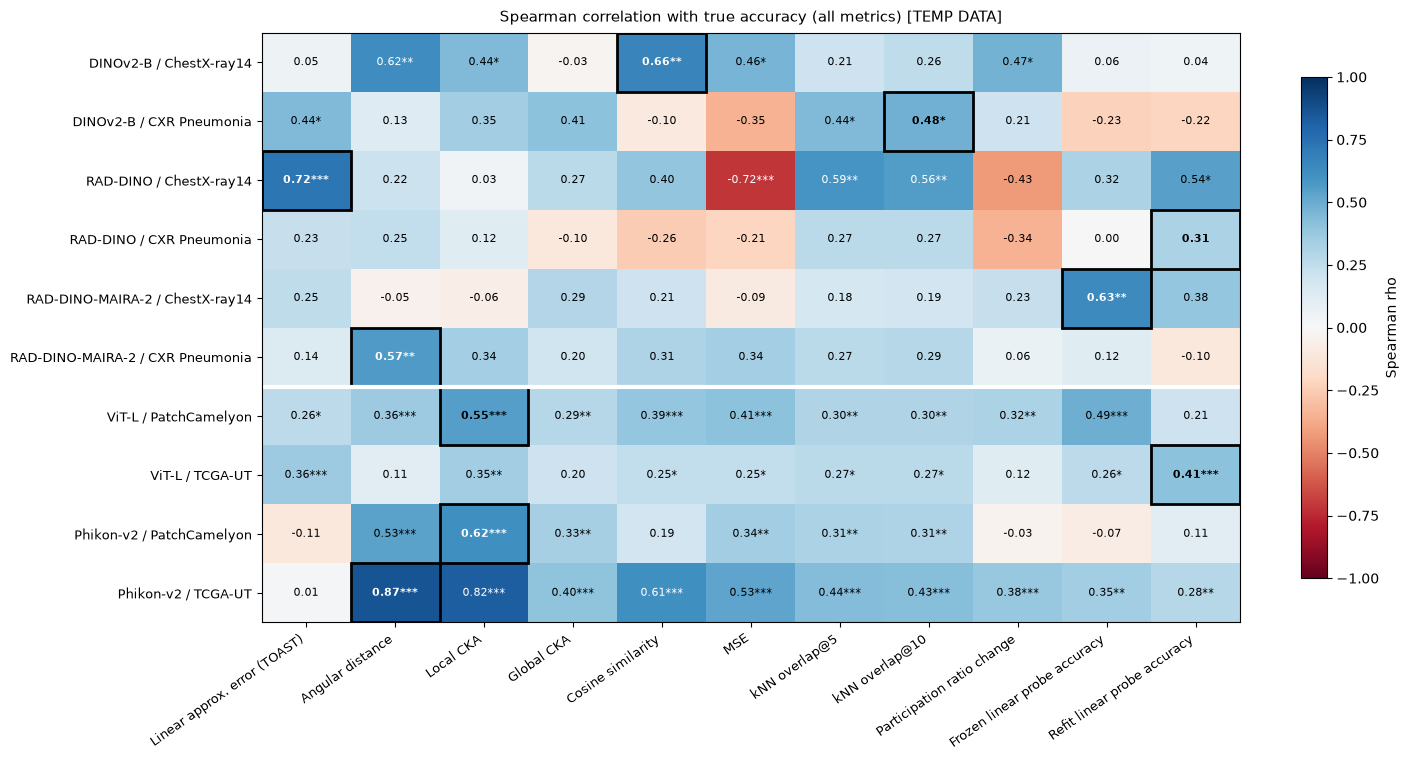

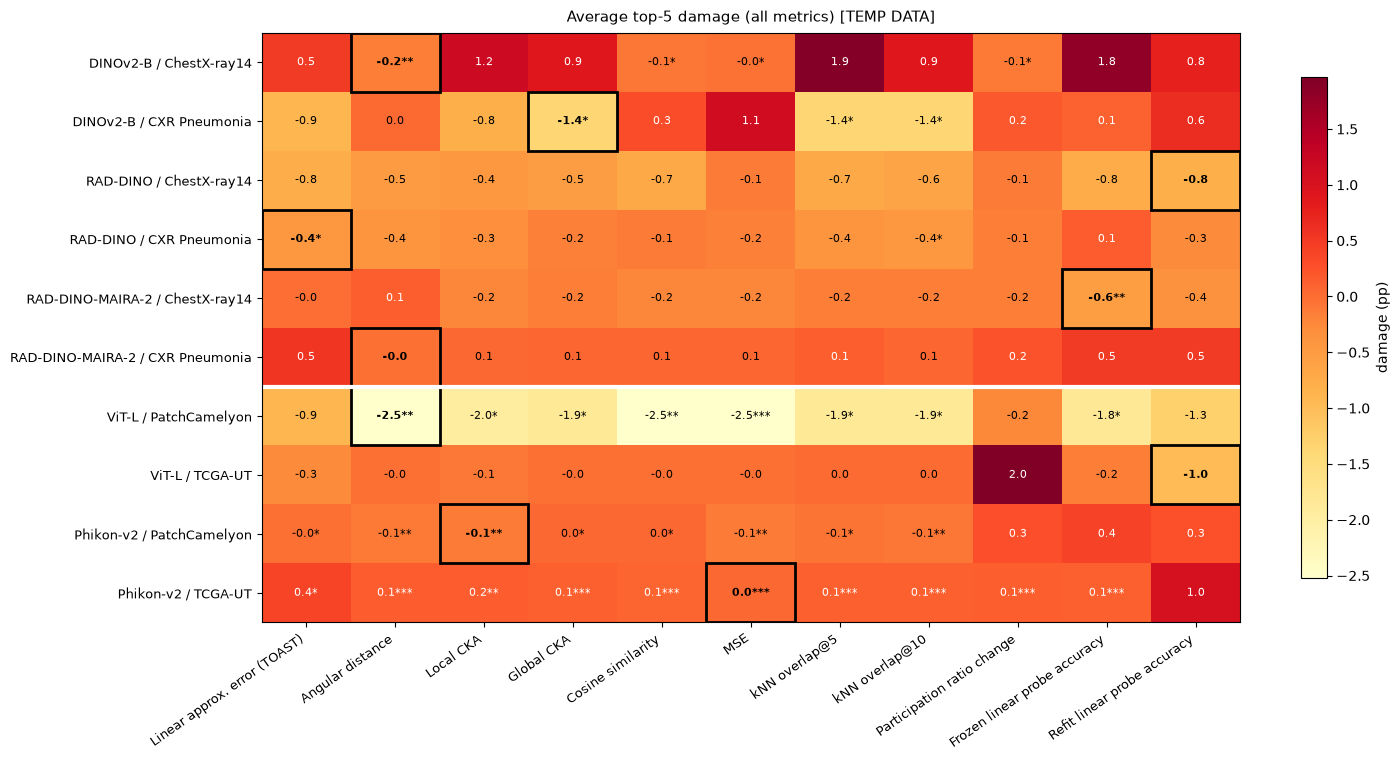

In [11]:
ALL_METRICS = {m: n for m, n in {**THESIS_METRICS, **OTHER_METRICS}.items()
               if m in df and df[m].notna().any()}
rho_all, rho_p_all, damage_all, damage_p_all = evaluate(ALL_METRICS)
heatmap(rho_all, f"Spearman correlation with true {TARGET_LABEL} (all metrics)", "Spearman rho", "RdBu",
        -1, 1, "{:.2f}", "max", ALL_METRICS, out="spearman_rho_all_metrics.png", pvals=rho_p_all)
heatmap(damage_all, "Average top-5 damage (all metrics)", "damage (pp)", "YlOrRd",
        min(0, np.nanmin(damage_all.values)), np.nanmax(damage_all.values), "{:.1f}", "min",
        ALL_METRICS, out="top5_damage_all_metrics.png", pvals=damage_p_all)